# CS 430 – Assignment 2: SLCM Regression Analysis
**Course:** CS-430-01 Machine Learning  |  **Target variable:** `past_due_rent`  |  **Dataset:** SLCM Rent Arrears De-identified Dataset

**Prediction question:** Can household, income, employment, and housing-related information help predict the amount of past-due rent?

*Data note: this is de-identified community data. Nothing here is a judgment about any individual or proof that one factor causes another.*

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# Part 1 – Get to Know the Prediction Problem

### 1. Load the dataset and examine its structure.
- Load the CSV file into pandas.
- Display the first 5 rows.
- Report the number of rows and columns.
- Print the column names.
- Use `info()` to inspect the dataset.

**Answer:** Which variable will be the target? Which columns appear to be numerical? Which columns appear to be categorical?

In [2]:
df = pd.read_csv("SLCM_rent_arrears_student_clean.csv")
display(df.head())
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
print("\nColumn names:", list(df.columns))
print()
df.info()

,record_id,adults_in_household,children_in_household,household_has_65plus,monthly_household_income,income_sources,employment_status,has_housing_voucher,eviction_in_progress,behind_on_utilities,main_reason_behind_on_rent,intake_quarter,monthly_rent,past_due_rent
0,SLCM_0001,1,1,No,293.0,"Food benefits - TANF/SNAP, No income, Other",Unemployed but want to find work,No,I don't know,Yes,Other,2026-Q1,1560.0,3100.0
1,SLCM_0002,0,3,No,2000.0,Child support,Employed,No,I don't know,Yes,Unexpected expense,2026-Q3,1550.0,7300.0
2,SLCM_0003,1,0,No,400.0,Food benefits - TANF/SNAP,Unemployed but want to find work,I don't know,Yes,Yes,Lost a job/had hours cut,2025-Q4,0.0,6000.0
3,SLCM_0004,2,0,No,2500.0,Full-time employment,Unemployed and not looking for work,No,Yes,Yes,Lost a job/had hours cut,2026-Q2,1299.0,2500.0
4,SLCM_0005,1,2,No,14.0,Part-time employment,Employed,No,Yes,No,Unexpected expense,2025-Q4,1105.5,1205.5


Rows: 1754, Columns: 14

Column names: ['record_id', 'adults_in_household', 'children_in_household', 'household_has_65plus', 'monthly_household_income', 'income_sources', 'employment_status', 'has_housing_voucher', 'eviction_in_progress', 'behind_on_utilities', 'main_reason_behind_on_rent', 'intake_quarter', 'monthly_rent', 'past_due_rent']

<class 'pandas.DataFrame'>
RangeIndex: 1754 entries, 0 to 1753
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   record_id                   1754 non-null   str    
 1   adults_in_household         1754 non-null   int64  
 2   children_in_household       1754 non-null   int64  
 3   household_has_65plus        1754 non-null   str    
 4   monthly_household_income    1646 non-null   float64
 5   income_sources              1754 non-null   str    
 6   employment_status           1754 non-null   str    
 7   has_housing_voucher         1754 non-null 

**Answer (Q1):**
- **Target:** `past_due_rent` (the dollar amount of rent a household is behind).
- **Numerical columns:** `adults_in_household`, `children_in_household`, `monthly_household_income`, `monthly_rent`, and the target `past_due_rent`.
- **Categorical columns:** `household_has_65plus`, `income_sources`, `employment_status`, `has_housing_voucher`, `eviction_in_progress`, `behind_on_utilities`, `main_reason_behind_on_rent`, and `intake_quarter` (a time period label, treated as a category).
- `record_id` is an identifier (text), not a real feature. The dataset has 1,754 rows and 14 columns.

### 2. Investigate missing values.
- Calculate the number of missing values in every column.
- Identify which variables contain missing data.
- Briefly describe how you plan to handle those missing values before modeling.

In [3]:
missing = df.isna().sum()
missing_df = pd.DataFrame({"missing_count": missing, "missing_pct": (missing / len(df) * 100).round(2)})
display(missing_df)
print("Columns with missing data:", missing[missing > 0].index.tolist())
print("\nZero values (real answers, not missing):")
print("  monthly_household_income == 0:", (df["monthly_household_income"] == 0).sum())
print("  monthly_rent == 0:", (df["monthly_rent"] == 0).sum())

,missing_count,missing_pct
record_id,0,0.00
adults_in_household,0,0.00
children_in_household,0,0.00
household_has_65plus,0,0.00
monthly_household_income,108,6.16
income_sources,0,0.00
employment_status,0,0.00
has_housing_voucher,0,0.00
eviction_in_progress,1,0.06
behind_on_utilities,7,0.40


Columns with missing data: ['monthly_household_income', 'eviction_in_progress', 'behind_on_utilities', 'main_reason_behind_on_rent', 'monthly_rent']

Zero values (real answers, not missing):
  monthly_household_income == 0: 440
  monthly_rent == 0: 45


**Answer (Q2):** Five columns have missing values: `monthly_household_income` (108, about 6.2%), `main_reason_behind_on_rent` (16), `monthly_rent` (8), `behind_on_utilities` (7), and `eviction_in_progress` (1). `past_due_rent` itself has none.

**Plan:** I will not drop rows. Dropping would throw away about 7% of the data (mostly because of income) and could bias the sample, since people who skip the income question may differ from those who answer. Instead, inside the pipeline:
- Missing **numerical** values (income, rent) are filled with the **median** of the training data. The median is used because income and rent are right-skewed.
- Missing **categorical** values are filled with the **most frequent** category of the training data.

Fitting the imputers inside the pipeline means they learn from the training set only, so no information leaks from the test set. Note that many households report $0 income (440) or $0 rent (45); those are real answers, not missing data, so they are kept as they are.

### 3. Explore the target variable: `past_due_rent`.
Calculate count, mean, median, standard deviation, minimum, maximum. Create a histogram and a boxplot.

**Answer:** What does the distribution look like? Is it symmetric or skewed? Are the mean and median similar? Do you notice any unusually high values? Why might rent-arrears data naturally contain a wide range of values?

,past_due_rent
count,1754.00
mean,2408.01
median,2000.00
std,2089.52
min,0.00
max,20000.00


Skewness: 2.96
Boxplot upper fence: $6,425;  rows above it: 61;  rows above $10,000: 17


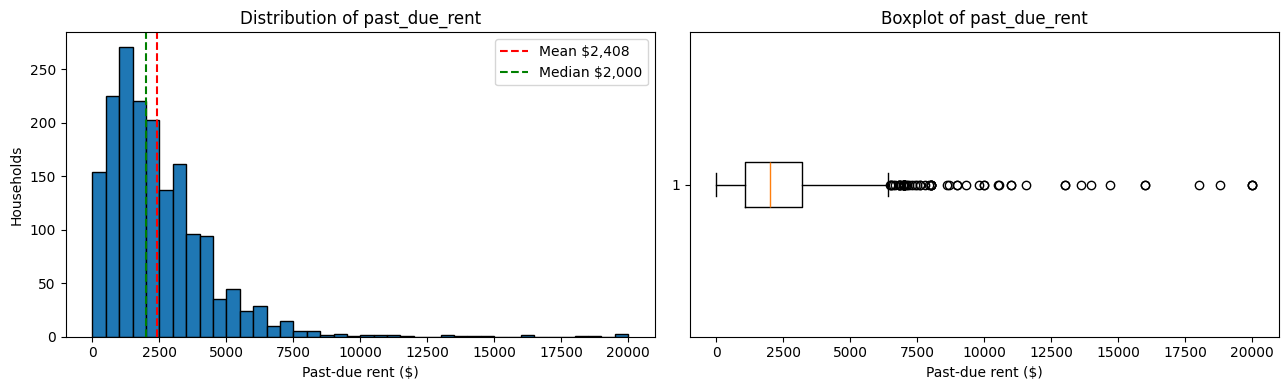

In [4]:
y_all = df["past_due_rent"]
stats = pd.Series({
    "count": y_all.count(), "mean": y_all.mean(), "median": y_all.median(),
    "std": y_all.std(), "min": y_all.min(), "max": y_all.max(),
})
display(stats.round(2).to_frame("past_due_rent"))
print("Skewness:", round(y_all.skew(), 2))
q1, q3 = y_all.quantile([0.25, 0.75])
fence = q3 + 1.5 * (q3 - q1)
print(f"Boxplot upper fence: ${fence:,.0f};  rows above it: {(y_all > fence).sum()};  rows above $10,000: {(y_all > 10000).sum()}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(y_all, bins=40, edgecolor="black")
ax[0].axvline(y_all.mean(), color="red", linestyle="--", label=f"Mean ${y_all.mean():,.0f}")
ax[0].axvline(y_all.median(), color="green", linestyle="--", label=f"Median ${y_all.median():,.0f}")
ax[0].set_title("Distribution of past_due_rent"); ax[0].set_xlabel("Past-due rent ($)"); ax[0].set_ylabel("Households"); ax[0].legend()
ax[1].boxplot(y_all, vert=False)
ax[1].set_title("Boxplot of past_due_rent"); ax[1].set_xlabel("Past-due rent ($)")
plt.tight_layout(); plt.show()

**Answer (Q3):**
- **Shape:** The histogram has a tall peak at lower amounts (roughly $1,000–$3,000) and a long tail stretching right to $20,000. The distribution is **strongly right-skewed** (skewness about 3.0), not symmetric.
- **Mean vs. median:** The mean (about $2,408) is above the median ($2,000), which is what right-skew produces: a few big values pull the mean up. The standard deviation (about $2,090) is nearly as large as the mean, showing wide spread.
- **High values:** The boxplot flags 61 households above about $6,425, and 17 are above $10,000, with a maximum of $20,000. I am keeping them. They are real households with real situations, not obvious data errors.
- **Why a wide range is natural:** Arrears accumulate over time. One household may be one month behind while another has been behind for many months, and rent levels, income shocks, and how soon someone reaches out for help all differ. Past-due rent is also bounded below at $0 but not capped above, which naturally produces a right-skewed shape.

# Part 2 – Prepare the Data for Machine Learning

### 4. Create your input features and target.
Create `X` and `y` using `past_due_rent` as the target. Do not use `record_id` as an input feature.

**Answer:** Why should `record_id` not be used to predict past-due rent?

In [5]:
y = df["past_due_rent"]
X = df.drop(columns=["record_id", "past_due_rent"])
print("X shape:", X.shape, "| y shape:", y.shape)
print("Features:", list(X.columns))

X shape: (1754, 12) | y shape: (1754,)
Features: ['adults_in_household', 'children_in_household', 'household_has_65plus', 'monthly_household_income', 'income_sources', 'employment_status', 'has_housing_voucher', 'eviction_in_progress', 'behind_on_utilities', 'main_reason_behind_on_rent', 'intake_quarter', 'monthly_rent']


**Answer (Q4):** `record_id` is just a label (SLCM_0001, SLCM_0002, ...) assigned to each row. It has no real-world meaning about a household's finances. If included, a model could treat the ID's position or number as a signal (for example, if the file happened to be ordered by date or by amount) and find a pattern that is an accident of how the file was built, not something that would hold for new households. It would also make the model less meaningful and less respectful of the de-identification, since it keys on an identifier rather than on household circumstances.

### 5. Separate the numerical and categorical features.
Create lists of numerical and categorical features, display both, and briefly explain why machine-learning models require different preparation for each.

In [6]:
numerical_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = [c for c in X.columns if c not in numerical_features]
print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['adults_in_household', 'children_in_household', 'monthly_household_income', 'monthly_rent']
Categorical features: ['household_has_65plus', 'income_sources', 'employment_status', 'has_housing_voucher', 'eviction_in_progress', 'behind_on_utilities', 'main_reason_behind_on_rent', 'intake_quarter']


**Answer (Q5):** Numerical variables are already numbers, but they sit on very different scales (children: 0–6, income: 0–10,000), so they need **imputation and scaling**. Categorical variables are text labels, which regression models cannot do math on, so they need **imputation and encoding** into numbers. The two kinds of columns need different tools, so they get separate preprocessing pipelines.

### 6. Split the data into training and testing sets.
Use `test_size=0.20` and `random_state=42`. Report the dimensions of `X_train`, `X_test`, `y_train`, and `y_test`.

**Answer:** Why should the model be evaluated using data that was not used during training?

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)

X_train: (1403, 12)
X_test:  (351, 12)
y_train: (1403,)
y_test:  (351,)


**Answer (Q6):** The split gives 1,403 training rows and 351 testing rows. A model can memorize quirks of the data it trained on, so its training score says little about how it would do on households it has never seen. Scoring on held-out test data gives an honest estimate of real-world performance and exposes overfitting. All four models below use this same split so the comparison is fair.

### 7. Prepare the numerical variables.
Create a numerical preprocessing pipeline that handles missing values and feature scaling (`SimpleImputer`, `StandardScaler`).

**Explain:** How did you handle missing numerical values? Why might feature scaling matter when comparing Linear, Ridge, and Lasso models?

In [8]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
numeric_transformer

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('imputer', ...), ('scaler', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a f

**Answer (Q7):** Missing income and rent values are filled with the **median** of the training data, which is not pulled around by the long tail of high values like a mean would be. Then `StandardScaler` rescales each feature to mean 0 and standard deviation 1. Scaling matters most for **Ridge and Lasso**: their penalties add up the sizes of the coefficients, so a feature measured in thousands of dollars would be penalized very differently from one measured in single-digit counts, purely because of its units. Putting everything on the same scale makes the penalty fair and also makes coefficients comparable. Ordinary Linear Regression gives the same predictions with or without scaling, but using the same scaled inputs keeps all four models comparable.

### 8. Prepare the categorical variables.
Create a categorical preprocessing pipeline that handles missing values and converts text categories into numbers (`SimpleImputer`, `OneHotEncoder`).

**Answer:** Why can the regression models not directly use values such as employment categories? Why is one-hot encoding appropriate? Why would assigning arbitrary numbers such as 1, 2, 3, 4 to unordered categories potentially be misleading?

In [9]:
print("Unique values in income_sources:", X["income_sources"].nunique())
print("Categories appearing fewer than 10 times:", (X["income_sources"].value_counts() < 10).sum())

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=10, sparse_output=False)),
])
categorical_transformer

Unique values in income_sources: 87
Categories appearing fewer than 10 times: 66


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('imputer', ...), ('onehot', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'most_frequent'
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation.

**Answer (Q8):**
- **Why text can't be used directly:** Regression multiplies each feature by a coefficient and adds them up. That requires numbers, and a string like "Employed" can't be multiplied.
- **Why one-hot encoding:** It turns each category into its own 0/1 column ("is this household Employed? yes/no"), so each category gets its own coefficient and no ordering is implied.
- **Why arbitrary integers mislead:** If Employed = 1, Unemployed = 2, Other = 3, the model would treat "Other" as three times "Employed" and assume a fixed, evenly spaced ordering that does not exist.
- **One design choice:** `income_sources` is a multi-select answer with 87 unique combinations, many of them appearing only once or twice. One-hot encoding all of them would create dozens of near-empty columns that invite overfitting. I used `min_frequency=10`, which groups any combination seen fewer than 10 times in the training data into a single "infrequent" column. `handle_unknown="ignore"` also means a category never seen in training will not crash the pipeline.

### 9. Combine your preprocessing steps.
Use a `ColumnTransformer` to combine the numerical and categorical preprocessing.

**Explain** briefly why using a preprocessing pipeline is useful.

In [10]:
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features),
])
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

**Answer (Q9):** A preprocessing pipeline bundles every cleaning step with the model so they always run in the same order. This keeps the code reusable across all four models, and it prevents **data leakage**: imputation values, scaling statistics, and category lists are learned only from the training data and then simply applied to the test data. It also means that new households can be passed straight into the pipeline as raw data, which is what Question 15 does.

# Part 3 – Build and Compare Regression Models

In [11]:
# Helper used for every model so evaluation is identical
def evaluate(model, name):
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)
    print(f"{name}:  RMSE = ${rmse:,.2f}   R² = {r2:.4f}")
    return preds, rmse, r2

# Reference point: always predicting the training-set mean
baseline_rmse = np.sqrt(mean_squared_error(y_test, np.full(len(y_test), y_train.mean())))
print(f"Baseline (predict the mean every time) RMSE = ${baseline_rmse:,.2f}")

Baseline (predict the mean every time) RMSE = $2,027.97


### 10. Build a Multiple Linear Regression model.
Create a pipeline with preprocessing and Linear Regression, train it, and predict the test set. Calculate RMSE and R². Create an Actual vs. Predicted scatterplot with a diagonal reference line.

**Answer:** What does RMSE represent? What does R² tell you? How closely do the predictions match? Are there cases with large errors?

Linear Regression:  RMSE = $1,850.00   R² = 0.1651


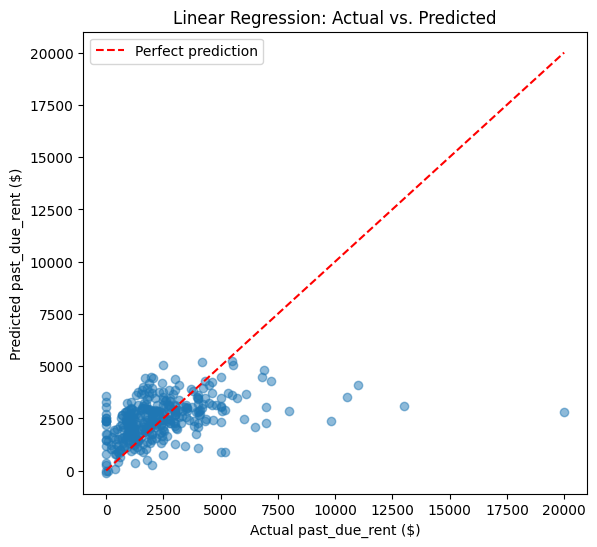

In [12]:
linear_pipe = Pipeline(steps=[("preprocess", preprocessor), ("model", LinearRegression())])
lin_preds, lin_rmse, lin_r2 = evaluate(linear_pipe, "Linear Regression")

plt.figure(figsize=(6.5, 6))
plt.scatter(y_test, lin_preds, alpha=0.5)
lims = [0, max(y_test.max(), lin_preds.max())]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual past_due_rent ($)"); plt.ylabel("Predicted past_due_rent ($)")
plt.title("Linear Regression: Actual vs. Predicted"); plt.legend(); plt.show()

**Answer (Q10):**
- **RMSE** (about $1,850) is the typical size of the model's prediction error, in dollars. Because errors are squared before averaging, big misses count extra. For comparison, always guessing the average gives an RMSE of about $2,028, so the model is only modestly better than guessing.
- **R²** (about 0.17) means the model explains only about 17% of the variation in past-due rent. The other 83% is driven by things not in the data.
- **Graph:** If predictions were accurate the points would hug the red diagonal. Instead they form a wide cloud, and predictions stay within a narrow band (roughly $0 to $5,500) no matter how large the actual value is.
- **Large errors:** Yes. Households with very large arrears (above $10,000) are predicted at only a few thousand dollars, so they are badly under-predicted. A few households with small actual values are over-predicted.

### 11. Build a Polynomial Regression model.
Use `PolynomialFeatures(degree=2, include_bias=False)` on the appropriate numerical variables, not on one-hot encoded categories. Train and calculate RMSE and R².

**Answer:** Did it perform better or worse than Linear? What does degree 2 allow? Why could a very high degree overfit? Did more complexity automatically make it better?

In [13]:
numeric_poly_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
])
preprocessor_poly = ColumnTransformer(transformers=[
    ("num", numeric_poly_transformer, numerical_features),   # polynomial only on numerical features
    ("cat", categorical_transformer, categorical_features),  # categories left as plain one-hot
])
poly_pipe = Pipeline(steps=[("preprocess", preprocessor_poly), ("model", LinearRegression())])
poly_preds, poly_rmse, poly_r2 = evaluate(poly_pipe, "Polynomial Regression (degree 2)")
n_num_poly = poly_pipe.named_steps["preprocess"].named_transformers_["num"].named_steps["poly"].n_output_features_
print(f"Numerical features expanded from {len(numerical_features)} to {n_num_poly}")

Polynomial Regression (degree 2):  RMSE = $1,865.30   R² = 0.1512
Numerical features expanded from 4 to 14


**Answer (Q11):**
- **Result:** Polynomial Regression did slightly **worse** than Linear (RMSE about $1,865 vs. $1,850; R² about 0.151 vs. 0.165).
- **What degree 2 adds:** It creates squared terms (e.g., rent²) and interaction terms (e.g., income × rent), so the model can represent curves and effects that depend on combinations of variables. Linear Regression can only fit a flat plane.
- **Overfitting risk:** A very high degree creates a huge number of terms and a very flexible curve that can bend to fit noise and individual odd households in the training set. It then does poorly on new data.
- **Complexity is not automatically better:** Here, the extra terms (4 numerical features expanded to 14) added flexibility without capturing any real pattern, and test performance dropped slightly. This suggests the relationships in this data are not strongly curved.

### 12. Build a Ridge Regression model.
Use the same train/test data and choose a reasonable `alpha` (you may experiment). Calculate RMSE and R².

**Answer:** How does Ridge compare with Linear? What does regularization do? Why is it useful with many features?

In [14]:
alphas = [0.1, 1, 10, 30, 100, 300, 1000]

# Choose alpha using 5-fold cross-validation on the TRAINING data only (test set stays untouched)
ridge_search = GridSearchCV(
    Pipeline([("preprocess", preprocessor), ("model", Ridge())]),
    param_grid={"model__alpha": alphas}, cv=5, scoring="neg_root_mean_squared_error",
).fit(X_train, y_train)
cv_ridge = pd.DataFrame({"alpha": alphas, "cv_RMSE": -ridge_search.cv_results_["mean_test_score"]})
display(cv_ridge.round(2))
best_ridge_alpha = ridge_search.best_params_["model__alpha"]
print("Best Ridge alpha (by CV):", best_ridge_alpha)

ridge_pipe = Pipeline(steps=[("preprocess", preprocessor), ("model", Ridge(alpha=best_ridge_alpha))])
ridge_preds, ridge_rmse, ridge_r2 = evaluate(ridge_pipe, f"Ridge Regression (alpha={best_ridge_alpha})")

,alpha,cv_RMSE
0,0.1,1944.46
1,1.0,1943.00
2,10.0,1935.23
3,30.0,1929.72
4,100.0,1928.17
5,300.0,1938.19
6,1000.0,1971.58


Best Ridge alpha (by CV): 100
Ridge Regression (alpha=100):  RMSE = $1,838.62   R² = 0.1753


**Answer (Q12):**
- **Compared with Linear:** Ridge (alpha chosen by cross-validation on the training data) is a bit better: RMSE about $1,839 vs. $1,850 and R² about 0.175 vs. 0.165. The improvement is small.
- **What regularization does:** It adds a penalty on the size of the coefficients, shrinking them toward zero so no single feature can have an extreme effect. Ridge shrinks coefficients but keeps all of them.
- **Why it helps with many features:** After one-hot encoding there are 55 input columns, many of them related to one another or rare. With many features, ordinary regression can assign large, unstable coefficients that fit noise. Shrinking them reduces variance and usually improves performance on new data.

### 13. Build a Lasso Regression model.
Same training/testing data, reasonable `alpha`. Calculate RMSE and R².

**Answer:** How does Lasso compare with Linear and Ridge? What is an important difference between Ridge and Lasso? What can happen to some coefficients?

In [15]:
lasso_alphas = [0.1, 1, 3, 10, 30, 100, 300]
lasso_search = GridSearchCV(
    Pipeline([("preprocess", preprocessor), ("model", Lasso(max_iter=20000))]),
    param_grid={"model__alpha": lasso_alphas}, cv=5, scoring="neg_root_mean_squared_error",
).fit(X_train, y_train)
cv_lasso = pd.DataFrame({"alpha": lasso_alphas, "cv_RMSE": -lasso_search.cv_results_["mean_test_score"]})
display(cv_lasso.round(2))
best_lasso_alpha = lasso_search.best_params_["model__alpha"]
print("Best Lasso alpha (by CV):", best_lasso_alpha)

lasso_pipe = Pipeline(steps=[("preprocess", preprocessor), ("model", Lasso(alpha=best_lasso_alpha, max_iter=20000))])
lasso_preds, lasso_rmse, lasso_r2 = evaluate(lasso_pipe, f"Lasso Regression (alpha={best_lasso_alpha})")

# Which coefficients did Lasso set to exactly zero?
feat_names = lasso_pipe.named_steps["preprocess"].get_feature_names_out()
coefs = pd.Series(lasso_pipe.named_steps["model"].coef_, index=feat_names)
print(f"\nLasso set {(coefs == 0).sum()} of {len(coefs)} coefficients to exactly zero")
print("\nLargest remaining coefficients:")
display(coefs[coefs != 0].sort_values(key=abs, ascending=False).head(8).round(1).to_frame("coefficient"))

,alpha,cv_RMSE
0,0.1,1944.87
1,1.0,1942.74
2,3.0,1939.07
3,10.0,1932.10
4,30.0,1933.63
5,100.0,1961.95
6,300.0,2009.78


Best Lasso alpha (by CV): 10
Lasso Regression (alpha=10):  RMSE = $1,825.62   R² = 0.1869

Lasso set 27 of 55 coefficients to exactly zero

Largest remaining coefficients:


,coefficient
cat__eviction_in_progress_I don't know,-757.2
num__monthly_rent,565.5
"cat__income_sources_Full-time employment, Social Security - SSI/SSDI",480.0
cat__intake_quarter_2025-Q1,447.8
cat__employment_status_Employed,367.1
cat__income_sources_infrequent_sklearn,265.7
cat__main_reason_behind_on_rent_Lost a job/had hours cut,215.4
cat__has_housing_voucher_Yes,-212.0


**Answer (Q13):**
- **Comparison:** Lasso has the best test results so far: RMSE about $1,826 and R² about 0.187, better than both Ridge ($1,839 / 0.175) and Linear ($1,850 / 0.165). Again the gap is small.
- **Ridge vs. Lasso:** Ridge only *shrinks* coefficients; Lasso uses an absolute-value penalty that can push coefficients all the way to **exactly zero**, which effectively removes those features and acts as automatic feature selection.
- **What happened here:** Lasso zeroed out about half of the 55 columns (the output above shows the exact count), keeping the ones that carried signal such as monthly rent. This produces a simpler model without losing accuracy.

### 14. Compare all four models.
Create a DataFrame containing the test-set results for all four models.

**Answer:** Which has the lowest RMSE? Highest R²? Are the differences large or small? Did the most complicated model perform the best? Which model would you continue investigating, and why?

,Model,RMSE,R²
0,Linear Regression,1850.00,0.1651
1,Polynomial Regression,1865.30,0.1512
2,Ridge Regression,1838.62,0.1753
3,Lasso Regression,1825.62,0.1869


Lowest RMSE : Lasso Regression
Highest R²  : Lasso Regression


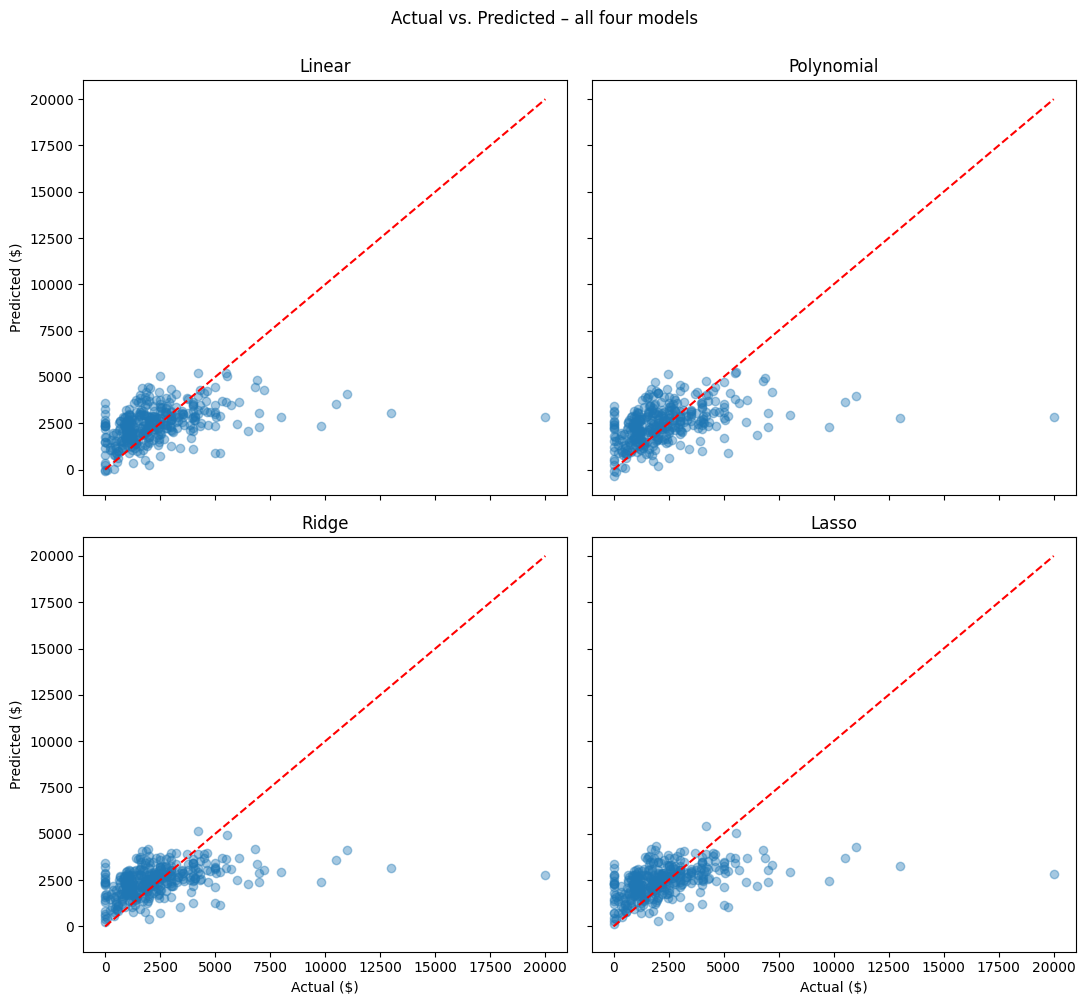

In [16]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Polynomial Regression", "Ridge Regression", "Lasso Regression"],
    "RMSE": [lin_rmse, poly_rmse, ridge_rmse, lasso_rmse],
    "R²": [lin_r2, poly_r2, ridge_r2, lasso_r2],
}).round({"RMSE": 2, "R²": 4})
display(results)
print("Lowest RMSE :", results.loc[results["RMSE"].idxmin(), "Model"])
print("Highest R²  :", results.loc[results["R²"].idxmax(), "Model"])

fig, axes = plt.subplots(2, 2, figsize=(11, 10), sharex=True, sharey=True)
for ax, (name, p) in zip(axes.ravel(), [("Linear", lin_preds), ("Polynomial", poly_preds), ("Ridge", ridge_preds), ("Lasso", lasso_preds)]):
    ax.scatter(y_test, p, alpha=0.4)
    ax.plot([0, y_test.max()], [0, y_test.max()], "r--")
    ax.set_title(name)
for ax in axes[1]: ax.set_xlabel("Actual ($)")
for ax in axes[:, 0]: ax.set_ylabel("Predicted ($)")
plt.suptitle("Actual vs. Predicted – all four models", y=1.0); plt.tight_layout(); plt.show()

**Answer (Q14):**
- **Lowest RMSE and highest R²:** Lasso Regression (RMSE about $1,826, R² about 0.187).
- **Size of differences:** Small. From best to worst the RMSE only spans about $40 (roughly 2% of the typical error), and all four R² values sit between about 0.15 and 0.19. The four scatterplots look nearly identical.
- **Most complicated model:** No. Polynomial Regression is the most complex and was the worst performer. The simpler regularized models did better.
- **Model to continue with:** **Lasso.** It has the best test RMSE and R², it is simple to explain, and it removes unhelpful features automatically. Its alpha was chosen with cross-validation on the training data rather than by looking at the test set. I would still treat the lead over Ridge as modest, since differences this small could change with a different random split.

### 15. Test your selected model on two hypothetical households.
Create TWO new hypothetical cases (not copied from the dataset) that differ in several characteristics. Predict `past_due_rent` for both.

**Explain:** How are the two households different? How different are the predictions? Does the difference seem reasonable?

In [17]:
selected_model = lasso_pipe   # selected in Question 14

hypothetical = pd.DataFrame([
    {   # Household A: small, working, has a voucher, current on utilities, lower rent
        "adults_in_household": 1, "children_in_household": 0, "household_has_65plus": "No",
        "monthly_household_income": 2800.0, "income_sources": "Full-time employment",
        "employment_status": "Employed", "has_housing_voucher": "Yes",
        "eviction_in_progress": "I don't know", "behind_on_utilities": "No",
        "main_reason_behind_on_rent": "Unexpected expense", "intake_quarter": "2026-Q3",
        "monthly_rent": 650.0,
    },
    {   # Household B: larger, lost job, no voucher, behind on utilities, higher rent
        "adults_in_household": 2, "children_in_household": 3, "household_has_65plus": "No",
        "monthly_household_income": 600.0, "income_sources": "Food benefits - TANF/SNAP",
        "employment_status": "Unemployed but want to find work", "has_housing_voucher": "No",
        "eviction_in_progress": "Yes", "behind_on_utilities": "Yes",
        "main_reason_behind_on_rent": "Lost a job/had hours cut", "intake_quarter": "2026-Q3",
        "monthly_rent": 1500.0,
    },
], index=["Household A", "Household B"])

hypothetical["predicted_past_due_rent"] = selected_model.predict(hypothetical[X.columns]).round(2)
display(hypothetical.T)
print(f"Difference (B - A): ${hypothetical['predicted_past_due_rent'].diff().iloc[-1]:,.2f}")

,Household A,Household B
adults_in_household,1,2
children_in_household,0,3
household_has_65plus,No,No
monthly_household_income,2800.0,600.0
income_sources,Full-time employment,Food benefits - TANF/SNAP
employment_status,Employed,Unemployed but want to find work
has_housing_voucher,Yes,No
eviction_in_progress,I don't know,Yes
behind_on_utilities,No,Yes
main_reason_behind_on_rent,Unexpected expense,Lost a job/had hours cut


Difference (B - A): $2,071.72


**Answer (Q15):**
- **How they differ:** Household A is one working adult with $2,800 monthly income, a housing voucher, a modest $650 rent, and no utility arrears. Household B is two adults and three children with $600 monthly income, no employment, no voucher, a $1,500 rent, utility arrears, and an eviction in progress.
- **Predictions:** Household A is predicted at about **$1,160** and Household B at about **$3,230**, a difference of roughly $2,070.
- **Reasonable?** The direction is sensible: B has much higher rent, far less income, and no voucher, which is the kind of situation where it is plausible that more rent is owed. Both predictions are also in a believable range compared with the dataset's median of $2,000. However, with an RMSE near $1,800, each prediction could easily be off by that much, so the *size* of the gap should not be over-interpreted. Predictions are patterns from past data, not a statement about any real household.

# Part 4 – Interpret the Results

### 16. What did your models tell you?
Address: best model, typical prediction errors, whether Polynomial helped, whether regularization helped, what the model predicts reasonably well, where it struggles.

In [18]:
# Evidence for Question 16: where do the selected model's errors fall?
err = pd.DataFrame({"actual": y_test.values, "predicted": lasso_preds})
err["error (pred - actual)"] = err["predicted"] - err["actual"]
bins = pd.cut(err["actual"], [-1, 1000, 3000, 6000, 20001], labels=["≤ $1,000", "$1,000–3,000", "$3,000–6,000", "> $6,000"])
display(err.groupby(bins, observed=True)["error (pred - actual)"].agg(["count", "mean"]).round(0).rename(columns={"mean": "average error ($)"}))
print(f"Mean absolute error: ${np.abs(err['error (pred - actual)']).mean():,.0f}")
print(f"Prediction range: ${err['predicted'].min():,.0f} to ${err['predicted'].max():,.0f}  |  Actual range: ${err['actual'].min():,.0f} to ${err['actual'].max():,.0f}")

,count,average error ($)
actual,,
"≤ $1,000",81,1272.0
"$1,000–3,000",188,522.0
"$3,000–6,000",69,-1211.0
"> $6,000",13,-5988.0


Mean absolute error: $1,179
Prediction range: $126 to $5,435  |  Actual range: $0 to $20,000


**Answer (Q16):**
- **Best model:** Lasso Regression (test RMSE about $1,826, R² about 0.187).
- **Typical error:** Roughly $1,800 (RMSE), or about $1,180 on average in absolute terms (MAE). Past-due rent has a median of $2,000, so that is a large error relative to the amounts being predicted. The model beats the "always guess the average" baseline (RMSE about $2,028), but only modestly.
- **Polynomial:** No meaningful improvement. It was slightly worse than Linear, so the extra complexity did not help.
- **Regularization:** It helped a little. Ridge and Lasso both beat plain Linear, and Lasso did best, but the gains were only about $10 to $25 in RMSE. They are consistent but small.
- **What it predicts reasonably well:** The middle of the distribution. For households owing roughly $1,000 to $3,000, the average error is modest, and the model picks up the general link between higher rent and higher arrears.
- **Where it struggles:** The extremes. The table above shows the model over-predicts households owing $1,000 or less (by about $1,270 on average), and badly under-predicts high-arrears households (about $1,200 too low for $3,000–6,000, and about $6,000 too low above $6,000). Predictions are squeezed into a narrow band ($100 to $5,400) while actual values reach $20,000. That is what we would expect when the available inputs capture only a small part of why someone falls far behind.

### 17. What is your overall finding for SLCM?
In 5–8 sentences, explain your analysis as if speaking to someone from SLCM who has not taken a machine-learning course.

**Answer (Q17):**

I tried to predict how much past-due rent a household owes when they come to SLCM, using information from their intake: how many adults and children are in the home, monthly income and rent, employment, income sources, whether they have a housing voucher, whether they are behind on utilities, whether an eviction is in progress, and their main reason for falling behind. The best model I built could explain only about 19% of the differences between households, and its typical miss was about $1,800, which is large when the typical household owes about $2,000. The most important finding is that the intake information helps a little, mostly through monthly rent, but most of what determines how far behind someone is, such as how many months they have gone unpaid or what happened to them, is not captured in these questions. Fancier models did not do better than simple ones, which tells me that collecting different information would help more than a more complicated model. Even so, a model like this could be useful for spotting general patterns in community needs and for planning how much assistance funding might be needed across many households. The main limitation is that it is not reliable for any one household, particularly those with very large arrears, so it should not be used to make decisions about individual people. These results also show patterns in this data only; they do not show that any factor causes a household to owe more or less rent.